
📂 Loading images from: fractured


100%|████████████████████████████████████████████████████████████████████████████████████████████| 4480/4480 [00:42<00:00, 104.29it/s]



📂 Loading images from: not_fractured


100%|████████████████████████████████████████████████████████████████████████████████████████████| 4383/4383 [00:41<00:00, 106.76it/s]



✅ Dataset loaded:
Images: (8863, 1764)  Labels: (8863,)
Classes: ['fractured', 'not_fractured']

🚀 Training Models...

📘 SVM Results:
Accuracy: 0.7688
Classification Report:
                precision    recall  f1-score   support

    fractured       0.80      0.72      0.76       896
not_fractured       0.74      0.82      0.78       877

     accuracy                           0.77      1773
    macro avg       0.77      0.77      0.77      1773
 weighted avg       0.77      0.77      0.77      1773



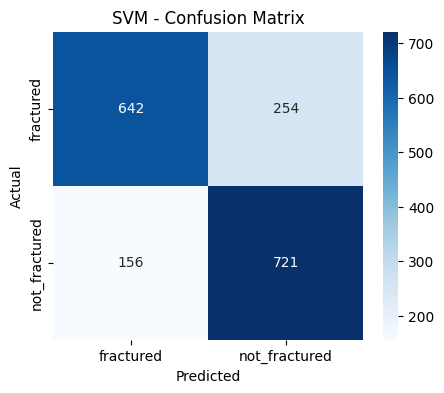


📘 Decision Tree Results:
Accuracy: 0.753
Classification Report:
                precision    recall  f1-score   support

    fractured       0.80      0.68      0.74       896
not_fractured       0.72      0.83      0.77       877

     accuracy                           0.75      1773
    macro avg       0.76      0.75      0.75      1773
 weighted avg       0.76      0.75      0.75      1773



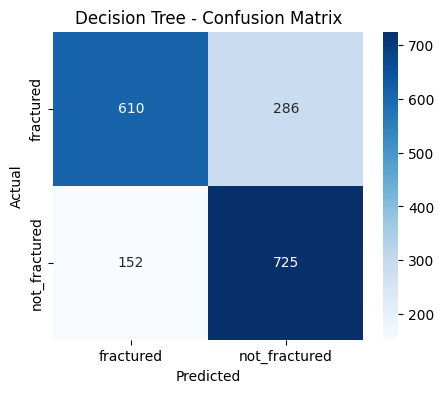


📘 Random Forest Results:
Accuracy: 0.9718
Classification Report:
                precision    recall  f1-score   support

    fractured       0.97      0.97      0.97       896
not_fractured       0.97      0.97      0.97       877

     accuracy                           0.97      1773
    macro avg       0.97      0.97      0.97      1773
 weighted avg       0.97      0.97      0.97      1773



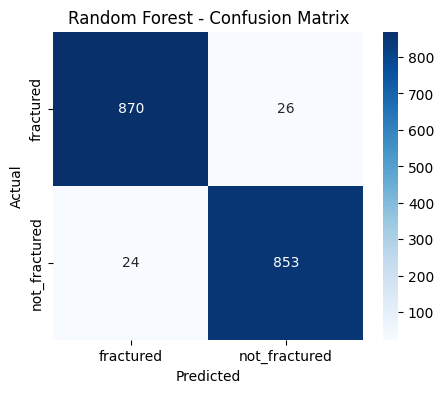


📘 K Neighbors Results:
Accuracy: 0.9915
Classification Report:
                precision    recall  f1-score   support

    fractured       1.00      0.99      0.99       896
not_fractured       0.99      1.00      0.99       877

     accuracy                           0.99      1773
    macro avg       0.99      0.99      0.99      1773
 weighted avg       0.99      0.99      0.99      1773



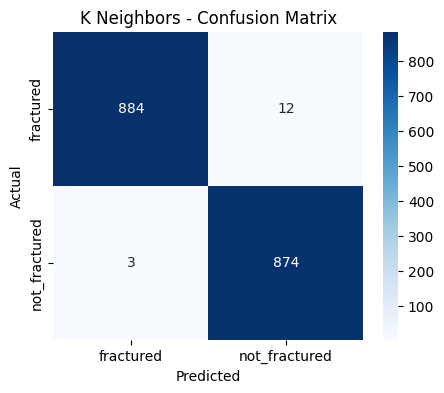


📘 Logistic Regression Results:
Accuracy: 0.7484
Classification Report:
                precision    recall  f1-score   support

    fractured       0.77      0.71      0.74       896
not_fractured       0.73      0.78      0.75       877

     accuracy                           0.75      1773
    macro avg       0.75      0.75      0.75      1773
 weighted avg       0.75      0.75      0.75      1773



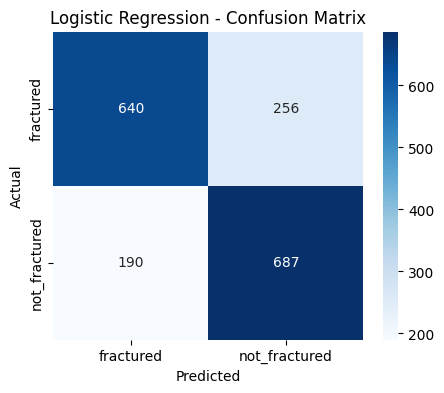


📘 SVM + KNN Results:
Accuracy: 0.9893
Classification Report:
                precision    recall  f1-score   support

    fractured       0.98      0.99      0.99       896
not_fractured       0.99      0.98      0.99       877

     accuracy                           0.99      1773
    macro avg       0.99      0.99      0.99      1773
 weighted avg       0.99      0.99      0.99      1773



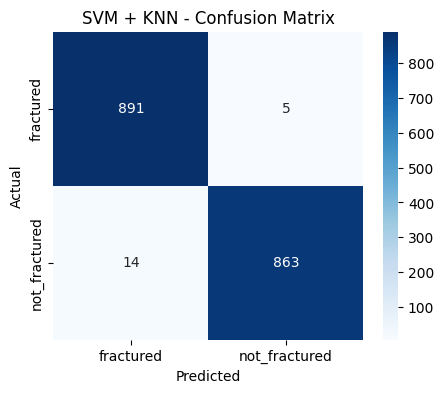


📘 XGBoost Results:
Accuracy: 0.9538
Classification Report:
                precision    recall  f1-score   support

    fractured       0.96      0.94      0.95       896
not_fractured       0.94      0.96      0.95       877

     accuracy                           0.95      1773
    macro avg       0.95      0.95      0.95      1773
 weighted avg       0.95      0.95      0.95      1773



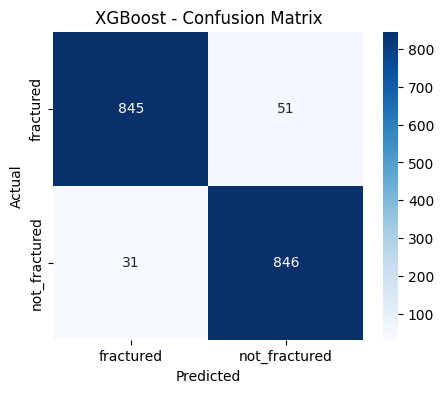


📘 Fusion (XGB + RF + Logistic) Results:
Accuracy: 0.9718
Classification Report:
                precision    recall  f1-score   support

    fractured       0.97      0.97      0.97       896
not_fractured       0.97      0.97      0.97       877

     accuracy                           0.97      1773
    macro avg       0.97      0.97      0.97      1773
 weighted avg       0.97      0.97      0.97      1773



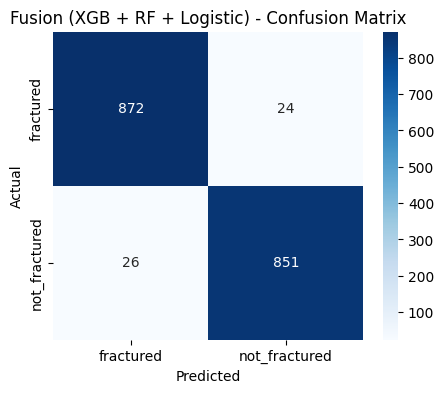

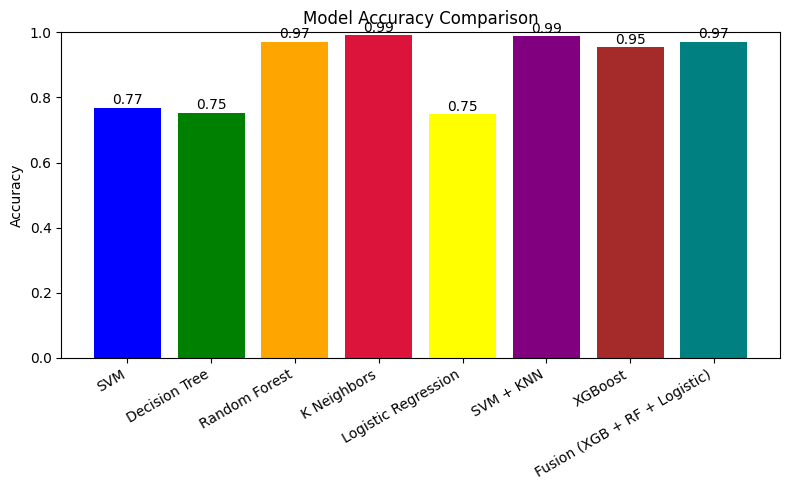


🏁 Training and Evaluation Complete!
✅ Models, PCA, and LabelEncoder saved in: saved_models


In [2]:
# ================================
# 🦴 Bone Fracture Detection Project (SVM-Centric Optimized)
# Models: SVM, Decision Tree, Random Forest
# Features: HOG + PCA
# Image Size: 64x64
# Dataset: Folder-based (fractured / not_fractured)
# ================================

import os
import cv2
import numpy as np
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from skimage.feature import hog
from tqdm import tqdm

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier,StackingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from xgboost import XGBClassifier

# =========================================
# Paths and save directory
# =========================================
base_path = "BoneFractureDataset/training"
save_dir = "saved_models"
os.makedirs(save_dir, exist_ok=True)

# =========================================
# Function to load dataset (from folders)
# =========================================
def load_dataset_from_folders(base_dir, img_size=(64,64)):
    X = []
    y = []
    class_names = sorted(os.listdir(base_dir))
    
    for label_name in class_names:
        folder_path = os.path.join(base_dir, label_name)
        if not os.path.isdir(folder_path):
            continue
        
        print(f"\n📂 Loading images from: {label_name}")
        for img_name in tqdm(os.listdir(folder_path)):
            if not img_name.lower().endswith(('.jpg', '.jpeg', '.png')):
                continue
            
            img_path = os.path.join(folder_path, img_name)
            img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
            if img is None:
                continue
            
            img = cv2.equalizeHist(cv2.resize(img, img_size))
            
            # Extract HOG features
            features = hog(img, orientations=9, pixels_per_cell=(8,8),
                           cells_per_block=(2,2), block_norm='L2-Hys', visualize=False)
            X.append(features)
            y.append(label_name)
    
    return np.array(X), np.array(y), class_names

# =========================================
# Load dataset
# =========================================
X, y, class_names = load_dataset_from_folders(base_path)
print("\n✅ Dataset loaded:")
print("Images:", X.shape, " Labels:", y.shape)
print("Classes:", class_names)

# =========================================
# Split Dataset (80% train, 20% test)
# =========================================
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,
                                                    stratify=y, random_state=42)

# =========================================
# Preprocessing
# =========================================
encoder = LabelEncoder()
y_train_enc = encoder.fit_transform(y_train)
y_test_enc = encoder.transform(y_test)
joblib.dump(encoder, os.path.join(save_dir, "label_encoder.pkl"))

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# PCA for dimensionality reduction
pca = PCA(n_components=150, random_state=42)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)
joblib.dump(pca, os.path.join(save_dir, "pca_transformer.pkl"))

# =========================================
# Model evaluation function
# =========================================
def evaluate_model(y_true, y_pred, model_name):
    acc = accuracy_score(y_true, y_pred)
    print(f"\n📘 {model_name} Results:")
    print("Accuracy:", round(acc,4))
    
    print("Classification Report:\n",
          classification_report(y_true, y_pred, target_names=class_names))
    
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(5,4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names)
    plt.title(f"{model_name} - Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()
    
    return acc

# =========================================
# Train Models
# =========================================
print("\n🚀 Training Models...")

# 1️⃣ SVM
svm_model = SVC(kernel='linear', C=1, class_weight='balanced', probability=True, random_state=42)
svm_model.fit(X_train_pca, y_train_enc)
y_pred_svm = svm_model.predict(X_test_pca)
acc_svm = evaluate_model(y_test_enc, y_pred_svm, "SVM")
joblib.dump(svm_model, os.path.join(save_dir, "svm_model.pkl"))

# 2️⃣ Decision Tree
dt_model = DecisionTreeClassifier(max_depth=10, random_state=42)
dt_model.fit(X_train_pca, y_train_enc)
y_pred_dt = dt_model.predict(X_test_pca)
acc_dt = evaluate_model(y_test_enc, y_pred_dt, "Decision Tree")
joblib.dump(dt_model, os.path.join(save_dir, "decision_tree_model.pkl"))

# 3️⃣ Random Forest
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train_pca, y_train_enc)
y_pred_rf = rf_model.predict(X_test_pca)
acc_rf = evaluate_model(y_test_enc, y_pred_rf, "Random Forest")
joblib.dump(rf_model, os.path.join(save_dir, "random_forest_model.pkl"))

# 4 KNN
knn_model = KNeighborsClassifier(n_neighbors=3)
knn_model.fit(X_train_pca, y_train_enc)
y_pred_knn = knn_model.predict(X_test_pca)
acc_knn = evaluate_model(y_test_enc, y_pred_knn, "K Neighbors")
joblib.dump(knn_model, os.path.join(save_dir, "knn_model.pkl"))

# 5 Logistic Regression
logistic_model = LogisticRegression()
logistic_model.fit(X_train_pca, y_train_enc)
y_pred_logistic = logistic_model.predict(X_test_pca)
acc_logistic = evaluate_model(y_test_enc, y_pred_logistic, "Logistic Regression")
joblib.dump(logistic_model, os.path.join(save_dir, "logistic_model.pkl"))

# 6 svm+rf
svm_knn_model = StackingClassifier(
    estimators=[('svm', SVC(probability=True, kernel='rbf', C=1.0, random_state=42)),
                ('knn', KNeighborsClassifier(n_neighbors=3))],
    final_estimator=KNeighborsClassifier(n_neighbors=3),
    cv=5)

svm_knn_model.fit(X_train_pca, y_train_enc)
y_pred_svm_knn = svm_knn_model.predict(X_test_pca)
svm_rf_acc = evaluate_model(y_test_enc, y_pred_svm_knn, "SVM + KNN")
joblib.dump(svm_knn_model, os.path.join(save_dir, "svm_knn_model.pkl"))

# 7 XGBOOST
xgb_model = XGBClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric='mlogloss'
)

xgb_model.fit(X_train_pca, y_train_enc)
y_pred_xgb = xgb_model.predict(X_test_pca)
acc_xgb = evaluate_model(y_test_enc, y_pred_xgb, "XGBoost")
joblib.dump(xgb_model, os.path.join(save_dir, "xgboost_model.pkl"))

# 8 Fusion Model (XGBoost + Random Forest + Logistic Regression)

fusion_model = StackingClassifier(
    estimators=[
        ('xgb', XGBClassifier(
            n_estimators=200,
            learning_rate=0.05,
            max_depth=6,
            subsample=0.8,
            colsample_bytree=0.8,
            random_state=42,
            eval_metric='mlogloss'
        )),
        ('rf', RandomForestClassifier(n_estimators=100, random_state=42)),
        ('logreg', LogisticRegression(max_iter=1000))
    ],
    final_estimator=LogisticRegression(max_iter=1000),
    cv=5
)

fusion_model.fit(X_train_pca, y_train_enc)
y_pred_fusion = fusion_model.predict(X_test_pca)
acc_fusion = evaluate_model(y_test_enc, y_pred_fusion, "Fusion (XGB + RF + Logistic)")
joblib.dump(fusion_model, os.path.join(save_dir, "fusion_model.pkl"))

# =========================================
# Compare Models
# =========================================
models = [
    'SVM', 
    'Decision Tree', 
    'Random Forest', 
    'K Neighbors',
    'Logistic Regression', 
    'SVM + KNN',
    'XGBoost',
    'Fusion (XGB + RF + Logistic)'
]

accuracies = [
    acc_svm, acc_dt, acc_rf, acc_knn, 
    acc_logistic, svm_rf_acc, 
    acc_xgb, acc_fusion
]

plt.figure(figsize=(8,5))
plt.bar(models, accuracies, color=['blue','green','orange','crimson','yellow','purple','brown','teal'])
plt.title('Model Accuracy Comparison')
plt.ylabel('Accuracy')
plt.ylim(0,1)
plt.xticks(rotation=30, ha='right')
for i, acc in enumerate(accuracies):
    plt.text(i, acc+0.01, f"{acc:.2f}", ha='center')
plt.tight_layout()
plt.show()

print("\n🏁 Training and Evaluation Complete!")
print("✅ Models, PCA, and LabelEncoder saved in:", save_dir)


In [2]:
# ================================
# 🦴 Bone Fracture Detection - Prediction GUI
# Uses trained models from saved_models/
# ================================

import os
import cv2
import numpy as np
import joblib
import tkinter as tk
from tkinter import filedialog, messagebox
from PIL import Image, ImageTk
from skimage.feature import hog
import matplotlib.pyplot as plt

# =========================================
# Configuration
# =========================================
IMG_SIZE = (64, 64)
MODEL_DIR = "saved_models"

# Load saved components
svm_model = joblib.load(os.path.join(MODEL_DIR, "svm_model.pkl"))
pca = joblib.load(os.path.join(MODEL_DIR, "pca_transformer.pkl"))
encoder = joblib.load(os.path.join(MODEL_DIR, "label_encoder.pkl"))

# =========================================
# Image Preprocessing + Feature Extraction
# =========================================
def preprocess_image(img_path):
    img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise ValueError("Unable to read image file.")
    
    img = cv2.equalizeHist(cv2.resize(img, IMG_SIZE))
    features = hog(img, orientations=9, pixels_per_cell=(8,8),
                   cells_per_block=(2,2), block_norm='L2-Hys', visualize=False)
    return features.reshape(1, -1), img

# =========================================
# Prediction Function
# =========================================
def predict_image(img_path):
    features, img = preprocess_image(img_path)
    
    # Apply PCA
    features_pca = pca.transform(features)
    
    # Predict with SVM
    pred_class = svm_model.predict(features_pca)[0]
    prob = svm_model.predict_proba(features_pca)[0]
    label_name = encoder.inverse_transform([pred_class])[0]
    
    return label_name, prob, img

# =========================================
# GUI
# =========================================
def open_file():
    file_path = filedialog.askopenfilename(
        title="Select X-ray Image",
        filetypes=[("Image Files", "*.jpg *.jpeg *.png")]
    )
    if not file_path:
        return
    
    try:
        label_name, prob, img = predict_image(file_path)
        
        # Show image in window
        img_rgb = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)
        img_pil = Image.fromarray(img_rgb)
        img_pil = img_pil.resize((256, 256))
        img_tk = ImageTk.PhotoImage(img_pil)
        
        img_label.config(image=img_tk)
        img_label.image = img_tk
        
        # Show prediction
        result_text.set(f"Prediction: {label_name.upper()}\nConfidence: {max(prob):.2f}")
    
    except Exception as e:
        messagebox.showerror("Error", f"Failed to process image:\n{e}")

# =========================================
# Create GUI window
# =========================================
root = tk.Tk()
root.title("🦴 Bone Fracture Detection (SVM)")
root.geometry("400x450")
root.resizable(False, False)

# Heading
tk.Label(root, text="Bone Fracture Detection", font=("Arial", 16, "bold")).pack(pady=10)

# Image Display
img_label = tk.Label(root)
img_label.pack(pady=10)

# Result Label
result_text = tk.StringVar()
tk.Label(root, textvariable=result_text, font=("Arial", 13), fg="blue").pack(pady=10)

# Button
tk.Button(root, text="Select Image", command=open_file, bg="#0078D7", fg="white",
          font=("Arial", 12, "bold"), width=15).pack(pady=10)

# Footer
tk.Label(root, text="Model: SVM (HOG + PCA)", font=("Arial", 9), fg="gray").pack(side="bottom", pady=10)

root.mainloop()


In [4]:
import joblib
joblib.load('saved_models/xgboost_model.pkl')


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='mlogloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=6, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=200, n_jobs=None,
              num_parallel_tree=None, ...)